# Decision Trees from Scratch vs. scikit-learn
Run from the `notebooks/` folder.

In [1]:
import sys; sys.path.append('..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from src.decision_tree import DecisionTree, gini, entropy
from src.utils import metrics

## 1. Data exploration

(569, 31) missing values: 0


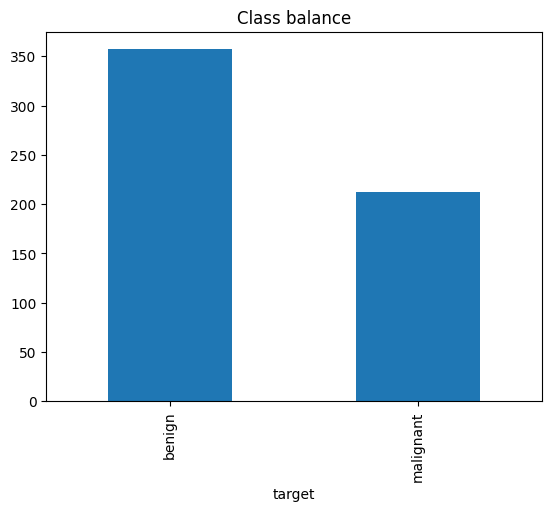

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame
print(df.shape, 'missing values:', int(df.isna().sum().sum()))
df['target'].map(dict(enumerate(data.target_names))).value_counts().plot.bar(title='Class balance');

In [3]:
df.groupby('target')[['mean radius','mean texture','worst radius','worst concave points']].mean()

,mean radius,mean texture,worst radius,worst concave points
target,,,,
0,17.462830,21.604906,21.134811,0.182237
1,12.146524,17.914762,13.379801,0.074444


## 2. Impurity measures
Gini = 1 - Σp², Entropy = -Σp·log₂p. Both peak at a 50/50 split.

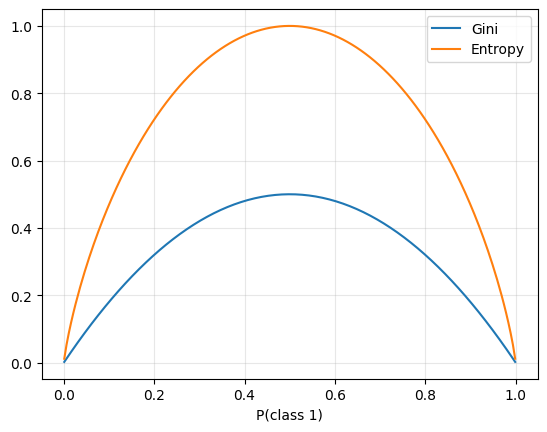

In [4]:
p=np.linspace(0.001,0.999,200)
plt.plot(p,1-p**2-(1-p)**2,label='Gini'); plt.plot(p,-p*np.log2(p)-(1-p)*np.log2(1-p),label='Entropy')
plt.xlabel('P(class 1)'); plt.legend(); plt.grid(alpha=.3);

## 3. Train and compare

In [5]:
X,y=data.data.values,data.target.values
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.25,random_state=42,stratify=y)
mine=DecisionTree('gini',max_depth=5).fit(Xtr,ytr)
sk=DecisionTreeClassifier(max_depth=5,random_state=42).fit(Xtr,ytr)
rf=RandomForestClassifier(n_estimators=200,random_state=42).fit(Xtr,ytr)
pd.DataFrame({'From scratch':metrics(yte,mine.predict(Xte)),'sklearn':metrics(yte,sk.predict(Xte)),'Random Forest':metrics(yte,rf.predict(Xte))}).T.round(4)

,accuracy,precision,recall,f1
From scratch,0.9371,0.9551,0.9444,0.9497
sklearn,0.9371,0.9551,0.9444,0.9497
Random Forest,0.9580,0.9565,0.9778,0.9670


In [6]:
print('Agreement with sklearn:', (mine.predict(Xte)==sk.predict(Xte)).mean())

Agreement with sklearn: 1.0


In [7]:
print(mine.export_text(list(data.feature_names), list(data.target_names)))

worst radius <= 16.795
|   worst concave points <= 0.136
|   |   radius error <= 1.048
|   |   |   radius error <= 0.626
|   |   |   |   smoothness error <= 0.003
|   |   |   |   |   class: benign  (n=4)
|   |   |   |   smoothness error >  0.003
|   |   |   |   |   class: benign  (n=243)
|   |   |   radius error >  0.626
|   |   |   |   mean texture <= 18.630
|   |   |   |   |   class: malignant  (n=1)
|   |   |   |   mean texture >  18.630
|   |   |   |   |   class: benign  (n=3)
|   |   radius error >  1.048
|   |   |   class: malignant  (n=1)
|   worst concave points >  0.136
|   |   worst texture <= 25.620
|   |   |   mean smoothness <= 0.123
|   |   |   |   worst area <= 817.100
|   |   |   |   |   class: benign  (n=9)
|   |   |   |   worst area >  817.100
|   |   |   |   |   class: malignant  (n=1)
|   |   |   mean smoothness >  0.123
|   |   |   |   class: malignant  (n=2)
|   |   worst texture >  25.620
|   |   |   worst symmetry <= 0.268
|   |   |   |   mean radius <= 14.440
|

## 4. Overfitting vs. depth

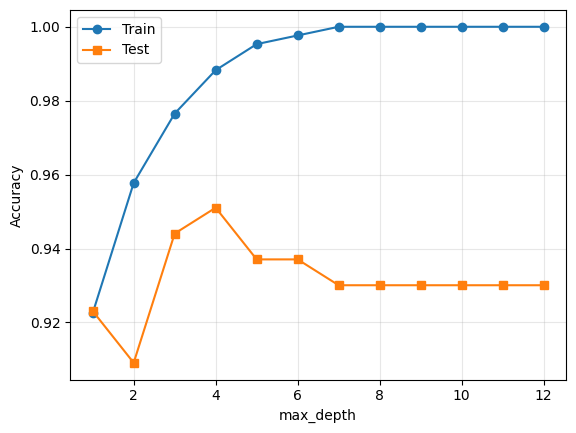

In [8]:
ds=range(1,13)
tr=[(DecisionTree(max_depth=d).fit(Xtr,ytr).predict(Xtr)==ytr).mean() for d in ds]
te=[(DecisionTree(max_depth=d).fit(Xtr,ytr).predict(Xte)==yte).mean() for d in ds]
plt.plot(ds,tr,'o-',label='Train'); plt.plot(ds,te,'s-',label='Test'); plt.xlabel('max_depth'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(alpha=.3);

## 5. Feature importance

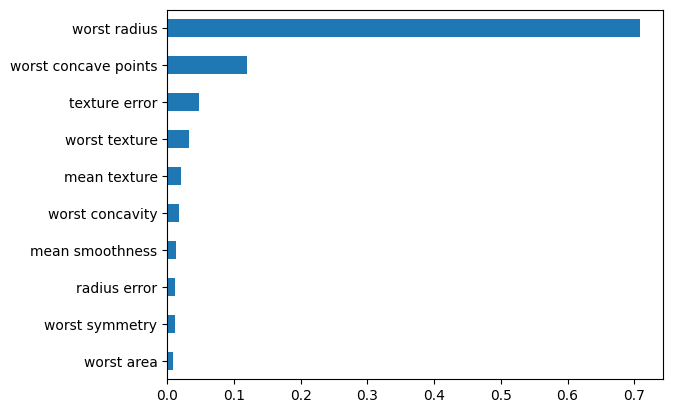

In [9]:
pd.Series(mine.feature_importances_,index=data.feature_names).nlargest(10).sort_values().plot.barh();